# Phase 3 — BiLSTM Sentiment Classification with SMOTE and 10 Config Experiments

**Dataset format expected**

| column | meaning |
|---|---|
| `id` | review identifier |
| `reviews` | cleaned/translated review text |
| `aspects` | verified aspect label |
| `sentiments` | verified sentiment label |

The Phase 3 design is:

```text
Input  = [ASPECT] aspect_name [REVIEW] review_text
Target = sentiment
Model  = BiLSTM sentiment classifier
SMOTE  = applied only on training features
```

This means the BiLSTM learns sentiment **conditioned on a specific aspect**.

Example:

```text
Input:  [ASPECT] Shipping [REVIEW] the package arrived very late
Target: Negative
```

## Why SMOTE is not applied to token IDs

SMOTE creates synthetic samples by interpolating numeric features.  
Applying SMOTE directly to integer token IDs is not valid because interpolated token IDs do not represent real words.

Therefore this notebook uses a safer pipeline:

```text
review + aspect text
→ TF-IDF vectorization
→ TruncatedSVD dense numeric features
→ SMOTE on training set only
→ reshape dense features as sequence
→ BiLSTM classifier
```

This still uses BiLSTM as the final classifier while keeping SMOTE mathematically valid.

In [2]:
import sys
import subprocess
import importlib.util

def install_if_missing(package_name, import_name=None):
    """
    Install a package only if it is missing.
    This keeps the notebook portable for VS Code, Colab, and Kaggle.
    """
    import_name = import_name or package_name
    if importlib.util.find_spec(import_name) is None:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])
    else:
        print(f"Already installed: {package_name}")

required_packages = [
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("scikit-learn", "sklearn"),
    ("imbalanced-learn", "imblearn"),
    ("torch", "torch"),
    ("tqdm", "tqdm"),
    ("joblib", "joblib"),
]

for package_name, import_name in required_packages:
    install_if_missing(package_name, import_name)

Already installed: numpy
Already installed: pandas
Already installed: matplotlib
Already installed: scikit-learn
Already installed: imbalanced-learn
Already installed: torch
Already installed: tqdm
Already installed: joblib


In [3]:
import os
import json
import random
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from tqdm.auto import tqdm

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)

from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
PyTorch: 2.12.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Configuration

In [4]:
# ============================================================
# Main configuration
# ============================================================

DATA_PATH = "C:\\Users\\Lenovo\\Documents\\Skripsi\\dataset\\phase3\\final_verified_shopee_dataset.csv"

OUTPUT_DIR = Path("C:\\Users\\Lenovo\\Documents\\Skripsi\\dataset\\phase3\\phase3_bilstm_smote_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# Split ratio:
# - test is held out until final evaluation
# - validation is used for config selection / early stopping
TEST_SIZE = 0.20
VAL_SIZE_FROM_TRAINVAL = 0.125  # 0.125 of 80% = 10% total validation

# Text feature extraction
MAX_TFIDF_FEATURES = 20000
N_SVD_COMPONENTS = 256

# Training
PATIENCE = 3
NUM_WORKERS = 0  # keep 0 for Windows/VS Code stability
PIN_MEMORY = True

# Set to True if you only want to test whether the notebook runs quickly.
FAST_DEBUG = False
DEBUG_SAMPLE_SIZE = 1200

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # CUDNN benchmark can make training faster but less deterministic.
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

set_seed(RANDOM_STATE)

print("DATA_PATH:", DATA_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR.resolve())
print("DEVICE:", DEVICE)

DATA_PATH: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\final_verified_shopee_dataset.csv
OUTPUT_DIR: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs
DEVICE: cuda


## 3. Load and validate dataset

In [5]:
df = pd.read_csv(DATA_PATH)

required_cols = ["id", "reviews", "aspects", "sentiments"]
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}. Found columns: {df.columns.tolist()}")

df = df[required_cols].copy()

# Basic cleaning
for col in required_cols:
    df[col] = df[col].astype(str).str.strip()

# Remove empty rows
df = df.replace({"": np.nan})
df = df.dropna(subset=["id", "reviews", "aspects", "sentiments"]).copy()

# Normalize sentiment capitalization
df["sentiments"] = df["sentiments"].str.capitalize()

# Your current final dataset should be binary.
# This line makes the notebook robust if an old Neutral row accidentally appears again.
allowed_sentiments = ["Negative", "Positive"]
before_filter = len(df)
df = df[df["sentiments"].isin(allowed_sentiments)].copy()
removed_rows = before_filter - len(df)

# Remove duplicate exact long-format rows
before_duplicates = len(df)
df = df.drop_duplicates(subset=["id", "reviews", "aspects", "sentiments"]).reset_index(drop=True)
duplicate_removed = before_duplicates - len(df)

if FAST_DEBUG and len(df) > DEBUG_SAMPLE_SIZE:
    df = df.sample(DEBUG_SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Unique reviews:", df["id"].nunique())
print("Removed non-binary/invalid sentiment rows:", removed_rows)
print("Removed exact duplicate rows:", duplicate_removed)
print("\nColumns:", df.columns.tolist())
display(df.head())

print("\nSentiment distribution:")
display(df["sentiments"].value_counts())

print("\nAspect distribution:")
display(df["aspects"].value_counts())

Dataset shape: (10781, 4)
Unique reviews: 7577
Removed non-binary/invalid sentiment rows: 0
Removed exact duplicate rows: 0

Columns: ['id', 'reviews', 'aspects', 'sentiments']


,id,reviews,aspects,sentiments
0,2d68668cf8c3d9b8,i hate your ads,App_experience,Negative
1,d363df62267eae48,"Shopee please do not raise the service fee, fr...",Pricing,Negative
2,d363df62267eae48,"Shopee please do not raise the service fee, fr...",Trust,Negative
3,8bdfe8eba767c20d,The most maximal apps have pop ads everywhere.,App_experience,Negative
4,c6e103e312de60a4,"Open the application, and then there's this li...",App_experience,Negative



Sentiment distribution:


sentiments
Negative    8324
Positive    2457
Name: count, dtype: int64


Aspect distribution:


aspects
App_experience              3583
Trust                       3122
Shipping                     936
Delivered_product_status     728
Pricing                      692
Customer_service             484
Item_quality                 381
Payment                      301
Information                  202
Product_features             150
Return_process                88
Product_availability          61
Refund_process                53
Name: count, dtype: int64

## 4. Exploratory visualization for skripsi

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\01_sentiment_distribution_before_smote.png


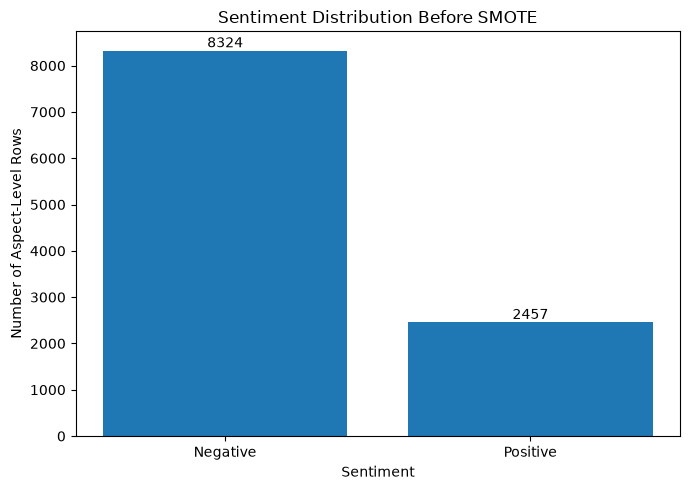

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\02_aspect_distribution.png


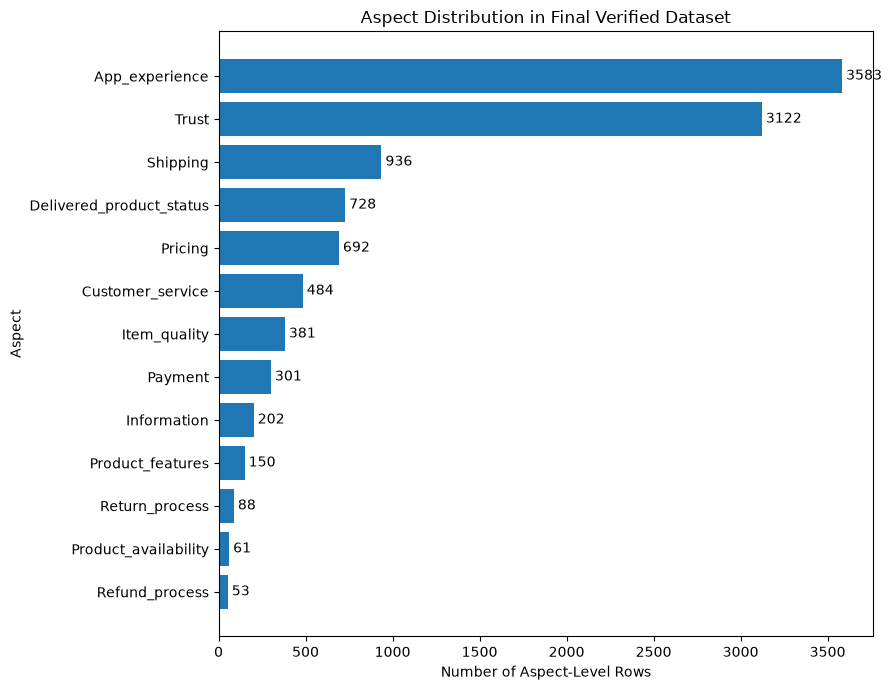

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\03_aspects_per_review_distribution.png


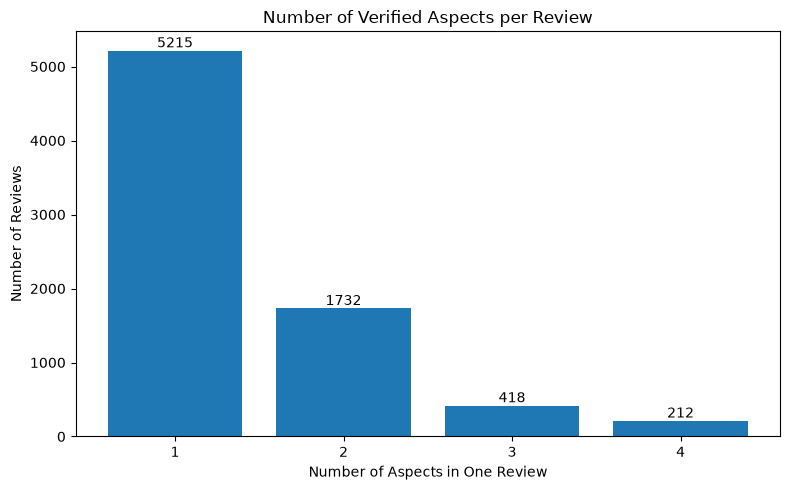

In [6]:
def save_current_fig(filename):
    path = OUTPUT_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved: {path}")
    plt.show()

# Sentiment distribution
sent_counts = df["sentiments"].value_counts().reindex(["Negative", "Positive"]).fillna(0)

plt.figure(figsize=(7, 5))
plt.bar(sent_counts.index, sent_counts.values)
plt.title("Sentiment Distribution Before SMOTE")
plt.xlabel("Sentiment")
plt.ylabel("Number of Aspect-Level Rows")
for i, v in enumerate(sent_counts.values):
    plt.text(i, v, str(int(v)), ha="center", va="bottom")
save_current_fig("01_sentiment_distribution_before_smote.png")

# Aspect distribution
aspect_counts = df["aspects"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(9, 7))
plt.barh(aspect_counts.index, aspect_counts.values)
plt.title("Aspect Distribution in Final Verified Dataset")
plt.xlabel("Number of Aspect-Level Rows")
plt.ylabel("Aspect")
for i, v in enumerate(aspect_counts.values):
    plt.text(v, i, f" {int(v)}", va="center")
save_current_fig("02_aspect_distribution.png")

# Review multi-aspect count distribution
review_aspect_counts = df.groupby("id")["aspects"].nunique().value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(review_aspect_counts.index.astype(str), review_aspect_counts.values)
plt.title("Number of Verified Aspects per Review")
plt.xlabel("Number of Aspects in One Review")
plt.ylabel("Number of Reviews")
for i, v in enumerate(review_aspect_counts.values):
    plt.text(i, v, str(int(v)), ha="center", va="bottom")
save_current_fig("03_aspects_per_review_distribution.png")

## 5. Build aspect-aware input text

The aspect is inserted before the review so the BiLSTM knows which aspect sentiment to classify.

In [7]:
df["model_text"] = (
    "[ASPECT] " + df["aspects"].astype(str) +
    " [REVIEW] " + df["reviews"].astype(str)
)

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["sentiments"])

label_mapping = {int(i): label for i, label in enumerate(label_encoder.classes_)}
print("Label mapping:", label_mapping)

with open(OUTPUT_DIR / "label_mapping.json", "w", encoding="utf-8") as f:
    json.dump(label_mapping, f, ensure_ascii=False, indent=2)

display(df[["id", "aspects", "sentiments", "label", "model_text"]].head())

Label mapping: {0: 'Negative', 1: 'Positive'}


,id,aspects,sentiments,label,model_text
0,2d68668cf8c3d9b8,App_experience,Negative,0,[ASPECT] App_experience [REVIEW] i hate your ads
1,d363df62267eae48,Pricing,Negative,0,[ASPECT] Pricing [REVIEW] Shopee please do not...
2,d363df62267eae48,Trust,Negative,0,[ASPECT] Trust [REVIEW] Shopee please do not r...
3,8bdfe8eba767c20d,App_experience,Negative,0,[ASPECT] App_experience [REVIEW] The most maxi...
4,c6e103e312de60a4,App_experience,Negative,0,[ASPECT] App_experience [REVIEW] Open the appl...


## 6. Grouped train/validation/test split

Important:

- Split is grouped by `id`.
- The same review cannot appear in train and test under different aspects.
- This prevents evaluation leakage.

In [8]:
def grouped_train_val_test_split(data, group_col="id", test_size=0.20, val_size_from_trainval=0.125, random_state=42):
    """
    Group-aware split by review id.
    This avoids the same review text appearing in multiple splits.
    """
    gss_test = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    trainval_idx, test_idx = next(gss_test.split(data, groups=data[group_col]))

    trainval_df = data.iloc[trainval_idx].reset_index(drop=True)
    test_df = data.iloc[test_idx].reset_index(drop=True)

    gss_val = GroupShuffleSplit(n_splits=1, test_size=val_size_from_trainval, random_state=random_state)
    train_idx, val_idx = next(gss_val.split(trainval_df, groups=trainval_df[group_col]))

    train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
    val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

    return train_df, val_df, test_df

train_df, val_df, test_df = grouped_train_val_test_split(
    df,
    group_col="id",
    test_size=TEST_SIZE,
    val_size_from_trainval=VAL_SIZE_FROM_TRAINVAL,
    random_state=RANDOM_STATE
)

def split_summary(name, part):
    return {
        "split": name,
        "rows": len(part),
        "unique_reviews": part["id"].nunique(),
        "negative": int((part["sentiments"] == "Negative").sum()),
        "positive": int((part["sentiments"] == "Positive").sum()),
        "negative_pct": round((part["sentiments"] == "Negative").mean() * 100, 2),
        "positive_pct": round((part["sentiments"] == "Positive").mean() * 100, 2),
    }

split_df = pd.DataFrame([
    split_summary("train", train_df),
    split_summary("validation", val_df),
    split_summary("test", test_df),
])

display(split_df)
split_df.to_csv(OUTPUT_DIR / "phase3_split_summary.csv", index=False, encoding="utf-8-sig")

# Safety check: no id leakage between splits
train_ids = set(train_df["id"])
val_ids = set(val_df["id"])
test_ids = set(test_df["id"])

assert train_ids.isdisjoint(val_ids), "Leakage detected: train and validation share review ids."
assert train_ids.isdisjoint(test_ids), "Leakage detected: train and test share review ids."
assert val_ids.isdisjoint(test_ids), "Leakage detected: validation and test share review ids."

print("No review-id leakage detected.")

,split,rows,unique_reviews,negative,positive,negative_pct,positive_pct
0,train,7593,5303,5880,1713,77.44,22.56
1,validation,1079,758,813,266,75.35,24.65
2,test,2109,1516,1631,478,77.34,22.66


No review-id leakage detected.


## 7. Text vectorization and dense feature extraction

Fit vectorizer/SVD/scaler on **training data only**.

This avoids data leakage.

In [9]:
X_train_text = train_df["model_text"].tolist()
X_val_text = val_df["model_text"].tolist()
X_test_text = test_df["model_text"].tolist()

y_train = train_df["label"].values.astype(np.int64)
y_val = val_df["label"].values.astype(np.int64)
y_test = test_df["label"].values.astype(np.int64)

# TF-IDF fitted on train only
vectorizer = TfidfVectorizer(
    max_features=MAX_TFIDF_FEATURES,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    strip_accents="unicode"
)

X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_val_tfidf = vectorizer.transform(X_val_text)
X_test_tfidf = vectorizer.transform(X_test_text)

# Make SVD component count safe
max_safe_components = min(N_SVD_COMPONENTS, X_train_tfidf.shape[1] - 1, X_train_tfidf.shape[0] - 1)
if max_safe_components < 2:
    raise ValueError("Not enough samples/features for TruncatedSVD. Check dataset size.")

print("TF-IDF train shape:", X_train_tfidf.shape)
print("Using SVD components:", max_safe_components)

svd = TruncatedSVD(n_components=max_safe_components, random_state=RANDOM_STATE)
X_train_svd = svd.fit_transform(X_train_tfidf)
X_val_svd = svd.transform(X_val_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

# Scaler fitted on train only
scaler = StandardScaler()
X_train_dense = scaler.fit_transform(X_train_svd).astype(np.float32)
X_val_dense = scaler.transform(X_val_svd).astype(np.float32)
X_test_dense = scaler.transform(X_test_svd).astype(np.float32)

print("Dense train shape:", X_train_dense.shape)
print("Dense val shape:", X_val_dense.shape)
print("Dense test shape:", X_test_dense.shape)

# Save preprocessing objects
joblib.dump(vectorizer, OUTPUT_DIR / "tfidf_vectorizer.joblib")
joblib.dump(svd, OUTPUT_DIR / "truncated_svd.joblib")
joblib.dump(scaler, OUTPUT_DIR / "standard_scaler.joblib")

print("Saved preprocessing objects.")

TF-IDF train shape: (7593, 20000)
Using SVD components: 256
Dense train shape: (7593, 256)
Dense val shape: (1079, 256)
Dense test shape: (2109, 256)
Saved preprocessing objects.


## 8. Apply SMOTE only to the training set

This is the key methodological rule for your skripsi:

```text
Train split → TF-IDF/SVD/scaler → SMOTE
Validation/test split → TF-IDF/SVD/scaler only, no SMOTE
```

Validation and test data must remain natural and untouched.

SMOTE k_neighbors: 5
Before SMOTE:
Negative    5880
Positive    1713
Name: count, dtype: int64

After SMOTE:
Negative    5880
Positive    5880
Name: count, dtype: int64


,before_smote,after_smote
Negative,5880,5880
Positive,1713,5880


Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\04_train_distribution_before_after_smote.png


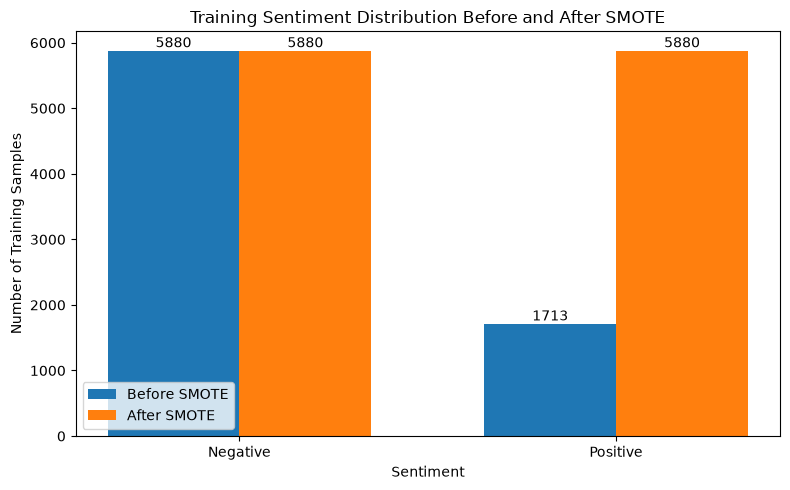

In [10]:
def apply_smote_to_training(X_train, y_train, random_state=42):
    class_counts = pd.Series(y_train).value_counts().sort_index()
    minority_count = int(class_counts.min())

    if minority_count < 2:
        raise ValueError("SMOTE requires at least 2 samples in the minority class.")

    k_neighbors = min(5, minority_count - 1)
    smote = SMOTE(random_state=random_state, k_neighbors=k_neighbors)

    X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

    print("SMOTE k_neighbors:", k_neighbors)
    print("Before SMOTE:")
    print(pd.Series(y_train).map(label_mapping).value_counts())
    print("\nAfter SMOTE:")
    print(pd.Series(y_resampled).map(label_mapping).value_counts())

    return X_resampled.astype(np.float32), y_resampled.astype(np.int64), smote

X_train_smote, y_train_smote, smote = apply_smote_to_training(
    X_train_dense,
    y_train,
    random_state=RANDOM_STATE
)

joblib.dump(smote, OUTPUT_DIR / "smote.joblib")

# Save before/after SMOTE counts
before_counts = pd.Series(y_train).map(label_mapping).value_counts().rename("before_smote")
after_counts = pd.Series(y_train_smote).map(label_mapping).value_counts().rename("after_smote")
smote_counts_df = pd.concat([before_counts, after_counts], axis=1).fillna(0).astype(int)
display(smote_counts_df)
smote_counts_df.to_csv(OUTPUT_DIR / "phase3_smote_distribution.csv", encoding="utf-8-sig")

# Visualization
labels = smote_counts_df.index.tolist()
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, smote_counts_df["before_smote"].values, width, label="Before SMOTE")
plt.bar(x + width/2, smote_counts_df["after_smote"].values, width, label="After SMOTE")
plt.title("Training Sentiment Distribution Before and After SMOTE")
plt.xlabel("Sentiment")
plt.ylabel("Number of Training Samples")
plt.xticks(x, labels)
plt.legend()

for i, v in enumerate(smote_counts_df["before_smote"].values):
    plt.text(i - width/2, v, str(int(v)), ha="center", va="bottom")
for i, v in enumerate(smote_counts_df["after_smote"].values):
    plt.text(i + width/2, v, str(int(v)), ha="center", va="bottom")

save_current_fig("04_train_distribution_before_after_smote.png")

## 9. Prepare BiLSTM dataset

The dense features are reshaped into a sequence so BiLSTM can process them.

Example:

```text
256 dense features → 16 time steps × 16 features
```

In [11]:
def reshape_dense_to_sequence(X, seq_steps):
    """
    Reshape dense vectors into sequence format for BiLSTM.

    If feature dimension is not divisible by seq_steps,
    zero-padding is added at the end.
    """
    n_samples, n_features = X.shape
    remainder = n_features % seq_steps

    if remainder != 0:
        pad_size = seq_steps - remainder
        X = np.pad(X, ((0, 0), (0, pad_size)), mode="constant")
        n_features = X.shape[1]

    step_dim = n_features // seq_steps
    return X.reshape(n_samples, seq_steps, step_dim).astype(np.float32)

class DenseSequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def make_loader(X, y, batch_size, shuffle=False):
    dataset = DenseSequenceDataset(X, y)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY and torch.cuda.is_available()
    )

## 10. Define BiLSTM model

In [12]:
class DenseBiLSTMClassifier(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dim,
        num_layers,
        num_classes,
        dropout=0.3,
        bidirectional=True,
        pooling="last"
    ):
        super().__init__()

        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1
        self.pooling = pooling

        lstm_dropout = dropout if num_layers > 1 else 0.0

        self.bilstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
            bidirectional=bidirectional
        )

        classifier_input_dim = hidden_dim * self.num_directions

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(classifier_input_dim, num_classes)

    def forward(self, x):
        output, (hidden, cell) = self.bilstm(x)

        if self.pooling == "mean":
            features = output.mean(dim=1)
        elif self.pooling == "max":
            features, _ = output.max(dim=1)
        else:
            if self.bidirectional:
                # Last layer forward and backward hidden states
                forward_hidden = hidden[-2]
                backward_hidden = hidden[-1]
                features = torch.cat([forward_hidden, backward_hidden], dim=1)
            else:
                features = hidden[-1]

        logits = self.fc(self.dropout(features))
        return logits

## 11. Training and evaluation helper functions

In [13]:
def predict_model(model, loader, device):
    model.eval()
    all_probs = []
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            logits = model(X_batch)
            probs = torch.softmax(logits, dim=1)

            preds = torch.argmax(probs, dim=1).cpu().numpy()

            all_probs.append(probs.cpu().numpy())
            all_preds.append(preds)
            all_targets.append(y_batch.numpy())

    all_probs = np.concatenate(all_probs, axis=0)
    all_preds = np.concatenate(all_preds, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    return all_targets, all_preds, all_probs


def compute_metrics(y_true, y_pred, y_prob=None):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

    # ROC-AUC only works reliably when both classes exist in y_true
    if y_prob is not None and len(np.unique(y_true)) == 2 and y_prob.shape[1] == 2:
        try:
            positive_index = list(label_encoder.classes_).index("Positive")
            metrics["roc_auc"] = roc_auc_score(y_true, y_prob[:, positive_index])
            metrics["average_precision"] = average_precision_score(y_true, y_prob[:, positive_index])
        except Exception:
            metrics["roc_auc"] = np.nan
            metrics["average_precision"] = np.nan
    else:
        metrics["roc_auc"] = np.nan
        metrics["average_precision"] = np.nan

    return metrics


def train_one_config(config, X_train, y_train, X_val, y_val, num_classes, device):
    set_seed(RANDOM_STATE)

    seq_steps = config["seq_steps"]

    X_train_seq = reshape_dense_to_sequence(X_train, seq_steps)
    X_val_seq = reshape_dense_to_sequence(X_val, seq_steps)

    input_dim = X_train_seq.shape[2]

    train_loader = make_loader(X_train_seq, y_train, batch_size=config["batch_size"], shuffle=True)
    val_loader = make_loader(X_val_seq, y_val, batch_size=config["batch_size"], shuffle=False)

    model = DenseBiLSTMClassifier(
        input_dim=input_dim,
        hidden_dim=config["hidden_dim"],
        num_layers=config["num_layers"],
        num_classes=num_classes,
        dropout=config["dropout"],
        bidirectional=config["bidirectional"],
        pooling=config["pooling"],
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )

    criterion = nn.CrossEntropyLoss()

    best_val_macro_f1 = -1
    best_state = None
    patience_counter = 0
    history = []

    for epoch in range(1, config["epochs"] + 1):
        model.train()
        train_losses = []

        progress = tqdm(train_loader, desc=f"{config['name']} | Epoch {epoch}/{config['epochs']}", leave=False)

        for X_batch, y_batch in progress:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()

            if config.get("grad_clip", None) is not None:
                nn.utils.clip_grad_norm_(model.parameters(), config["grad_clip"])

            optimizer.step()

            train_losses.append(loss.item())
            progress.set_postfix(loss=f"{loss.item():.4f}")

        # Evaluate train and validation after each epoch
        train_eval_loader = make_loader(X_train_seq, y_train, batch_size=config["batch_size"], shuffle=False)

        y_train_true, y_train_pred, y_train_prob = predict_model(model, train_eval_loader, device)
        y_val_true, y_val_pred, y_val_prob = predict_model(model, val_loader, device)

        train_metrics = compute_metrics(y_train_true, y_train_pred, y_train_prob)
        val_metrics = compute_metrics(y_val_true, y_val_pred, y_val_prob)

        row = {
            "config_name": config["name"],
            "epoch": epoch,
            "train_loss": float(np.mean(train_losses)),
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "train_weighted_f1": train_metrics["weighted_f1"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "val_weighted_f1": val_metrics["weighted_f1"],
            "val_roc_auc": val_metrics["roc_auc"],
            "val_average_precision": val_metrics["average_precision"],
        }

        history.append(row)

        print(
            f"{config['name']} | Epoch {epoch:02d} | "
            f"loss={row['train_loss']:.4f} | "
            f"train_macro_f1={row['train_macro_f1']:.4f} | "
            f"val_macro_f1={row['val_macro_f1']:.4f} | "
            f"val_acc={row['val_accuracy']:.4f}"
        )

        if row["val_macro_f1"] > best_val_macro_f1:
            best_val_macro_f1 = row["val_macro_f1"]
            best_state = {
                "model_state_dict": model.state_dict(),
                "config": config,
                "input_dim": input_dim,
                "seq_steps": seq_steps,
                "best_epoch": epoch,
                "best_val_macro_f1": best_val_macro_f1,
            }
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            print(f"Early stopping triggered for {config['name']} at epoch {epoch}.")
            break

    # Load best state back into model before returning
    model.load_state_dict(best_state["model_state_dict"])

    history_df = pd.DataFrame(history)

    best_history_row = history_df.sort_values(
        ["val_macro_f1", "val_weighted_f1", "val_accuracy"],
        ascending=False
    ).iloc[0].to_dict()

    return model, best_state, history_df, best_history_row

## 12. Define 10 BiLSTM configurations

Config:

- sequence reshaping size
- hidden dimension
- number of BiLSTM layers
- dropout
- learning rate
- pooling strategy
- batch size

In [14]:
CONFIGS = [
    {
        "name": "config_01_small_last",
        "seq_steps": 16,
        "hidden_dim": 64,
        "num_layers": 1,
        "dropout": 0.20,
        "bidirectional": True,
        "pooling": "last",
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 10,
        "grad_clip": 1.0,
    },
    {
        "name": "config_02_small_mean",
        "seq_steps": 16,
        "hidden_dim": 64,
        "num_layers": 1,
        "dropout": 0.30,
        "bidirectional": True,
        "pooling": "mean",
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 10,
        "grad_clip": 1.0,
    },
    {
        "name": "config_03_medium_last",
        "seq_steps": 16,
        "hidden_dim": 128,
        "num_layers": 1,
        "dropout": 0.30,
        "bidirectional": True,
        "pooling": "last",
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 10,
        "grad_clip": 1.0,
    },
    {
        "name": "config_04_medium_mean",
        "seq_steps": 16,
        "hidden_dim": 128,
        "num_layers": 1,
        "dropout": 0.40,
        "bidirectional": True,
        "pooling": "mean",
        "lr": 8e-4,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 10,
        "grad_clip": 1.0,
    },
    {
        "name": "config_05_medium_2layer",
        "seq_steps": 16,
        "hidden_dim": 128,
        "num_layers": 2,
        "dropout": 0.40,
        "bidirectional": True,
        "pooling": "last",
        "lr": 8e-4,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 12,
        "grad_clip": 1.0,
    },
    {
        "name": "config_06_large_last",
        "seq_steps": 16,
        "hidden_dim": 192,
        "num_layers": 1,
        "dropout": 0.40,
        "bidirectional": True,
        "pooling": "last",
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 12,
        "grad_clip": 1.0,
    },
    {
        "name": "config_07_large_mean",
        "seq_steps": 16,
        "hidden_dim": 192,
        "num_layers": 1,
        "dropout": 0.50,
        "bidirectional": True,
        "pooling": "mean",
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 12,
        "grad_clip": 1.0,
    },
    {
        "name": "config_08_seq8",
        "seq_steps": 8,
        "hidden_dim": 128,
        "num_layers": 1,
        "dropout": 0.30,
        "bidirectional": True,
        "pooling": "last",
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 10,
        "grad_clip": 1.0,
    },
    {
        "name": "config_09_seq32",
        "seq_steps": 32,
        "hidden_dim": 128,
        "num_layers": 1,
        "dropout": 0.30,
        "bidirectional": True,
        "pooling": "last",
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 64,
        "epochs": 10,
        "grad_clip": 1.0,
    },
    {
        "name": "config_10_deeper_regularized",
        "seq_steps": 16,
        "hidden_dim": 160,
        "num_layers": 2,
        "dropout": 0.50,
        "bidirectional": True,
        "pooling": "mean",
        "lr": 5e-4,
        "weight_decay": 5e-4,
        "batch_size": 128,
        "epochs": 12,
        "grad_clip": 1.0,
    },
]

if FAST_DEBUG:
    for cfg in CONFIGS:
        cfg["epochs"] = 2
    CONFIGS = CONFIGS[:2]

pd.DataFrame(CONFIGS)

,name,seq_steps,hidden_dim,num_layers,dropout,bidirectional,pooling,lr,weight_decay,batch_size,epochs,grad_clip
0,config_01_small_last,16,64,1,0.2,True,last,0.0010,0.0001,64,10,1.0
1,config_02_small_mean,16,64,1,0.3,True,mean,0.0010,0.0001,64,10,1.0
2,config_03_medium_last,16,128,1,0.3,True,last,0.0010,0.0001,64,10,1.0
3,config_04_medium_mean,16,128,1,0.4,True,mean,0.0008,0.0001,64,10,1.0
4,config_05_medium_2layer,16,128,2,0.4,True,last,0.0008,0.0001,64,12,1.0
5,config_06_large_last,16,192,1,0.4,True,last,0.0005,0.0001,64,12,1.0
6,config_07_large_mean,16,192,1,0.5,True,mean,0.0005,0.0001,64,12,1.0
7,config_08_seq8,8,128,1,0.3,True,last,0.0010,0.0001,64,10,1.0
8,config_09_seq32,32,128,1,0.3,True,last,0.0010,0.0001,64,10,1.0
9,config_10_deeper_regularized,16,160,2,0.5,True,mean,0.0005,0.0005,128,12,1.0


## 13. Run 10 configuration experiments

The best config is selected by validation `macro_f1`, because the data is imbalanced.

In [15]:
num_classes = len(label_encoder.classes_)

all_histories = []
summary_rows = []
best_overall = {
    "val_macro_f1": -1,
    "model": None,
    "state": None,
    "config": None,
    "history": None,
}

for config in CONFIGS:
    print("=" * 90)
    print("Training:", config["name"])
    print(json.dumps(config, indent=2))
    print("=" * 90)

    model, best_state, history_df, best_row = train_one_config(
        config=config,
        X_train=X_train_smote,
        y_train=y_train_smote,
        X_val=X_val_dense,
        y_val=y_val,
        num_classes=num_classes,
        device=DEVICE,
    )

    history_path = OUTPUT_DIR / f"history_{config['name']}.csv"
    history_df.to_csv(history_path, index=False, encoding="utf-8-sig")

    all_histories.append(history_df)

    summary_row = {
        **{f"param_{k}": v for k, v in config.items()},
        "best_epoch": int(best_state["best_epoch"]),
        "best_val_macro_f1": float(best_state["best_val_macro_f1"]),
        "best_val_accuracy": float(best_row["val_accuracy"]),
        "best_val_weighted_f1": float(best_row["val_weighted_f1"]),
        "best_val_roc_auc": float(best_row["val_roc_auc"]) if not pd.isna(best_row["val_roc_auc"]) else np.nan,
        "best_val_average_precision": float(best_row["val_average_precision"]) if not pd.isna(best_row["val_average_precision"]) else np.nan,
    }
    summary_rows.append(summary_row)

    # Save config-specific best checkpoint
    torch.save(best_state, OUTPUT_DIR / f"checkpoint_{config['name']}.pt")

    if best_state["best_val_macro_f1"] > best_overall["val_macro_f1"]:
        best_overall = {
            "val_macro_f1": best_state["best_val_macro_f1"],
            "model": model,
            "state": best_state,
            "config": config,
            "history": history_df.copy(),
        }

    # Clean GPU memory between configs
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(summary_rows)
results_df = results_df.sort_values(
    ["best_val_macro_f1", "best_val_weighted_f1", "best_val_accuracy"],
    ascending=False
).reset_index(drop=True)

display(results_df)

results_df.to_csv(OUTPUT_DIR / "phase3_10_config_validation_results.csv", index=False, encoding="utf-8-sig")
pd.concat(all_histories, ignore_index=True).to_csv(OUTPUT_DIR / "phase3_all_training_histories.csv", index=False, encoding="utf-8-sig")

# Save best model
torch.save(best_overall["state"], OUTPUT_DIR / "phase3_best_bilstm_smote_model.pt")

with open(OUTPUT_DIR / "phase3_best_config.json", "w", encoding="utf-8") as f:
    json.dump(best_overall["config"], f, indent=2)

print("Best config:", best_overall["config"]["name"])
print("Best validation macro F1:", best_overall["val_macro_f1"])

Training: config_01_small_last
{
  "name": "config_01_small_last",
  "seq_steps": 16,
  "hidden_dim": 64,
  "num_layers": 1,
  "dropout": 0.2,
  "bidirectional": true,
  "pooling": "last",
  "lr": 0.001,
  "weight_decay": 0.0001,
  "batch_size": 64,
  "epochs": 10,
  "grad_clip": 1.0
}


config_01_small_last | Epoch 1/10:   0%|          | 0/184 [00:00<?, ?it/s]

config_01_small_last | Epoch 01 | loss=0.4685 | train_macro_f1=0.8738 | val_macro_f1=0.8013 | val_acc=0.8424


config_01_small_last | Epoch 2/10:   0%|          | 0/184 [00:00<?, ?it/s]

config_01_small_last | Epoch 02 | loss=0.2932 | train_macro_f1=0.8986 | val_macro_f1=0.7899 | val_acc=0.8276


...

config_10_deeper_regularized | Epoch 07 | loss=0.2679 | train_macro_f1=0.8964 | val_macro_f1=0.7336 | val_acc=0.7674


config_10_deeper_regularized | Epoch 8/12:   0%|          | 0/92 [00:00<?, ?it/s]

config_10_deeper_regularized | Epoch 08 | loss=0.2518 | train_macro_f1=0.9178 | val_macro_f1=0.7719 | val_acc=0.8146
Early stopping triggered for config_10_deeper_regularized at epoch 8.


,param_name,param_seq_steps,param_hidden_dim,param_num_layers,param_dropout,param_bidirectional,param_pooling,param_lr,param_weight_decay,param_batch_size,param_epochs,param_grad_clip,best_epoch,best_val_macro_f1,best_val_accuracy,best_val_weighted_f1,best_val_roc_auc,best_val_average_precision
0,config_08_seq8,8,128,1,0.3,True,last,0.0010,0.0001,64,10,1.0,8,0.841215,0.883225,0.882620,0.923531,0.838229
1,config_09_seq32,32,128,1,0.3,True,last,0.0010,0.0001,64,10,1.0,7,0.840339,0.881372,0.881372,0.915924,0.808975
2,config_06_large_last,16,192,1,0.4,True,last,0.0005,0.0001,64,12,1.0,7,0.839698,0.880445,0.880670,0.932932,0.841437
3,config_03_medium_last,16,128,1,0.3,True,last,0.0010,0.0001,64,10,1.0,4,0.835496,0.872104,0.874837,0.929783,0.825885
4,config_01_small_last,16,64,1,0.2,True,last,0.0010,0.0001,64,10,1.0,7,0.818863,0.861909,0.863628,0.908396,0.796467
5,config_05_medium_2layer,16,128,2,0.4,True,last,0.0008,0.0001,64,12,1.0,7,0.814758,0.860982,0.861668,0.904531,0.796720
6,config_02_small_mean,16,64,1,0.3,True,mean,0.0010,0.0001,64,10,1.0,7,0.789084,0.841520,0.842397,0.888078,0.749091
7,config_04_medium_mean,16,128,1,0.4,True,mean,0.0008,0.0001,64,10,1.0,4,0.781683,0.835959,0.836867,0.891440,0.758895
8,config_07_large_mean,16,192,1,0.5,True,mean,0.0005,0.0001,64,12,1.0,7,0.779196,0.820204,0.827435,0.895625,0.754442
9,config_10_deeper_regularized,16,160,2,0.5,True,mean,0.0005,0.0005,128,12,1.0,5,0.777153,0.815570,0.824059,0.897391,0.775171


Best config: config_08_seq8
Best validation macro F1: 0.8412153008119446


## 14. Visualize 10-config validation comparison

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\05_config_comparison_validation_macro_f1.png


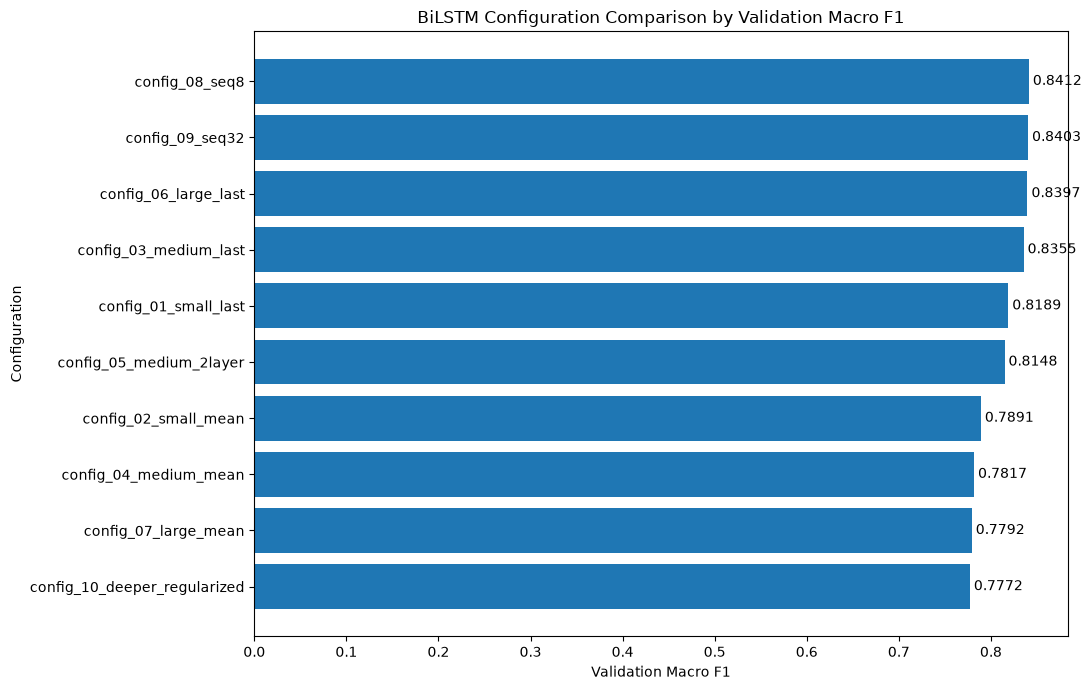

,param_name,best_epoch,best_val_accuracy,best_val_macro_f1,best_val_weighted_f1,best_val_roc_auc,param_hidden_dim,param_num_layers,param_dropout,param_lr,param_seq_steps,param_pooling,param_batch_size
0,config_08_seq8,8,0.883225,0.841215,0.882620,0.923531,128,1,0.3,0.0010,8,last,64
1,config_09_seq32,7,0.881372,0.840339,0.881372,0.915924,128,1,0.3,0.0010,32,last,64
2,config_06_large_last,7,0.880445,0.839698,0.880670,0.932932,192,1,0.4,0.0005,16,last,64
3,config_03_medium_last,4,0.872104,0.835496,0.874837,0.929783,128,1,0.3,0.0010,16,last,64
4,config_01_small_last,7,0.861909,0.818863,0.863628,0.908396,64,1,0.2,0.0010,16,last,64
5,config_05_medium_2layer,7,0.860982,0.814758,0.861668,0.904531,128,2,0.4,0.0008,16,last,64
6,config_02_small_mean,7,0.841520,0.789084,0.842397,0.888078,64,1,0.3,0.0010,16,mean,64
7,config_04_medium_mean,4,0.835959,0.781683,0.836867,0.891440,128,1,0.4,0.0008,16,mean,64
8,config_07_large_mean,7,0.820204,0.779196,0.827435,0.895625,192,1,0.5,0.0005,16,mean,64
9,config_10_deeper_regularized,5,0.815570,0.777153,0.824059,0.897391,160,2,0.5,0.0005,16,mean,128


In [16]:
plot_results = results_df.sort_values("best_val_macro_f1", ascending=True)

plt.figure(figsize=(11, 7))
plt.barh(plot_results["param_name"], plot_results["best_val_macro_f1"])
plt.title("BiLSTM Configuration Comparison by Validation Macro F1")
plt.xlabel("Validation Macro F1")
plt.ylabel("Configuration")

for i, v in enumerate(plot_results["best_val_macro_f1"].values):
    plt.text(v, i, f" {v:.4f}", va="center")

save_current_fig("05_config_comparison_validation_macro_f1.png")

# Comparison table with only important columns
important_cols = [
    "param_name",
    "best_epoch",
    "best_val_accuracy",
    "best_val_macro_f1",
    "best_val_weighted_f1",
    "best_val_roc_auc",
    "param_hidden_dim",
    "param_num_layers",
    "param_dropout",
    "param_lr",
    "param_seq_steps",
    "param_pooling",
    "param_batch_size",
]

display(results_df[important_cols])

## 15. Visualize training curve of the best config

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\06_best_config_training_loss_curve.png


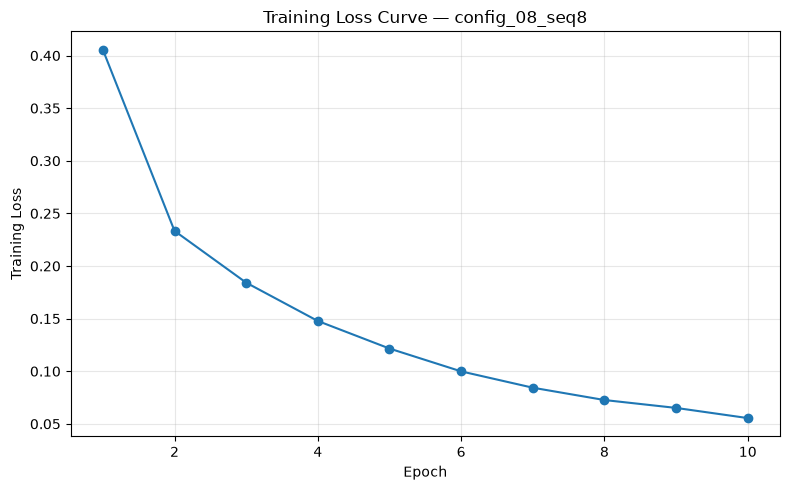

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\07_best_config_macro_f1_curve.png


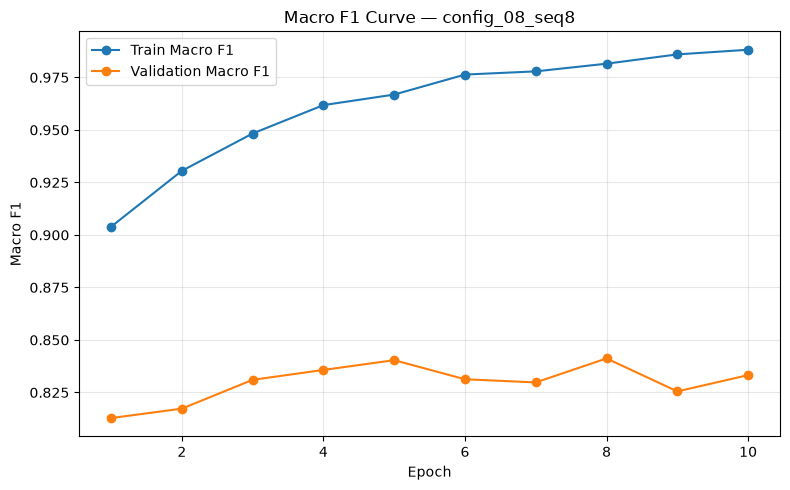

In [17]:
best_history = best_overall["history"].copy()
best_name = best_overall["config"]["name"]

plt.figure(figsize=(8, 5))
plt.plot(best_history["epoch"], best_history["train_loss"], marker="o")
plt.title(f"Training Loss Curve — {best_name}")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.grid(True, alpha=0.3)
save_current_fig("06_best_config_training_loss_curve.png")

plt.figure(figsize=(8, 5))
plt.plot(best_history["epoch"], best_history["train_macro_f1"], marker="o", label="Train Macro F1")
plt.plot(best_history["epoch"], best_history["val_macro_f1"], marker="o", label="Validation Macro F1")
plt.title(f"Macro F1 Curve — {best_name}")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.grid(True, alpha=0.3)
save_current_fig("07_best_config_macro_f1_curve.png")

## 16. Final test evaluation using the best config

The test set is used only once after selecting the best configuration.

In [18]:
best_config = best_overall["config"]
best_state = best_overall["state"]

# Rebuild best model from checkpoint to make evaluation fully reproducible
X_test_seq = reshape_dense_to_sequence(X_test_dense, best_config["seq_steps"])
X_val_seq = reshape_dense_to_sequence(X_val_dense, best_config["seq_steps"])

input_dim = X_test_seq.shape[2]

best_model = DenseBiLSTMClassifier(
    input_dim=input_dim,
    hidden_dim=best_config["hidden_dim"],
    num_layers=best_config["num_layers"],
    num_classes=num_classes,
    dropout=best_config["dropout"],
    bidirectional=best_config["bidirectional"],
    pooling=best_config["pooling"],
).to(DEVICE)

best_model.load_state_dict(best_state["model_state_dict"])

test_loader = make_loader(X_test_seq, y_test, batch_size=best_config["batch_size"], shuffle=False)

y_true, y_pred, y_prob = predict_model(best_model, test_loader, DEVICE)
test_metrics = compute_metrics(y_true, y_pred, y_prob)

print("Final test metrics:")
for k, v in test_metrics.items():
    print(f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}")

test_metrics_json = {k: float(v) if isinstance(v, (np.floating, float)) and not pd.isna(v) else None for k, v in test_metrics.items()}

with open(OUTPUT_DIR / "phase3_best_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_metrics_json, f, indent=2)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()
display(report_df)
report_df.to_csv(OUTPUT_DIR / "phase3_best_test_classification_report.csv", encoding="utf-8-sig")

test_pred_df = test_df.copy()
test_pred_df["true_sentiment"] = label_encoder.inverse_transform(y_true)
test_pred_df["pred_sentiment"] = label_encoder.inverse_transform(y_pred)

for idx, label in label_mapping.items():
    test_pred_df[f"prob_{label}"] = y_prob[:, idx]

test_pred_df["is_correct"] = test_pred_df["true_sentiment"] == test_pred_df["pred_sentiment"]

display(test_pred_df.head())
test_pred_df.to_csv(OUTPUT_DIR / "phase3_test_predictions.csv", index=False, encoding="utf-8-sig")

Final test metrics:
accuracy: 0.8720
macro_f1: 0.8195
weighted_f1: 0.8727
roc_auc: 0.9182
average_precision: 0.8004


,precision,recall,f1-score,support
Negative,0.921362,0.912324,0.916821,1631.000000
Positive,0.710526,0.734310,0.722222,478.000000
accuracy,0.871977,0.871977,0.871977,0.871977
macro avg,0.815944,0.823317,0.819521,2109.000000
weighted avg,0.873577,0.871977,0.872715,2109.000000


,id,reviews,aspects,sentiments,model_text,label,true_sentiment,pred_sentiment,prob_Negative,prob_Positive,is_correct
0,2d68668cf8c3d9b8,i hate your ads,App_experience,Negative,[ASPECT] App_experience [REVIEW] i hate your ads,0,Negative,Negative,1.000000,1.968020e-09,True
1,7d4ac7de6da3b5fb,We thank you very much for the online service ...,Customer_service,Positive,[ASPECT] Customer_service [REVIEW] We thank yo...,1,Positive,Positive,0.000455,9.995449e-01,True
2,4c33eb575e77aadc,"It's ugly, it's old enough to be here, it's 10...",Shipping,Negative,"[ASPECT] Shipping [REVIEW] It's ugly, it's old...",0,Negative,Negative,0.998644,1.356373e-03,True
3,4c33eb575e77aadc,"It's ugly, it's old enough to be here, it's 10...",Trust,Negative,"[ASPECT] Trust [REVIEW] It's ugly, it's old en...",0,Negative,Negative,0.997448,2.551646e-03,True
4,1ea72367461217e5,Shopee has become my main marketplace shop in ...,Trust,Positive,[ASPECT] Trust [REVIEW] Shopee has become my m...,1,Positive,Positive,0.024094,9.759064e-01,True


## 17. Confusion matrix visualization

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\08_best_model_confusion_matrix.png


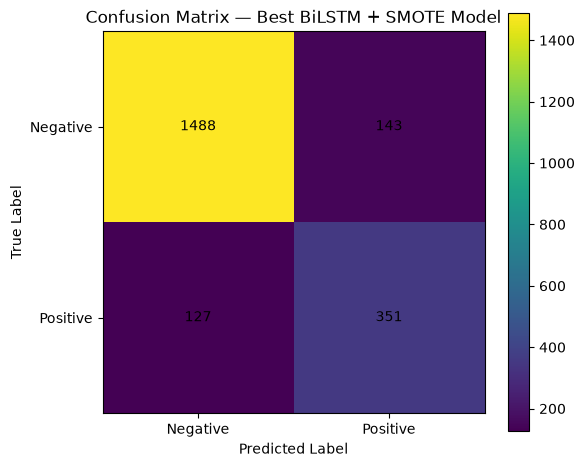

In [19]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
class_names = label_encoder.classes_

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix — Best BiLSTM + SMOTE Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(num_classes), class_names)
plt.yticks(range(num_classes), class_names)

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.colorbar()
save_current_fig("08_best_model_confusion_matrix.png")

## 18. ROC and Precision-Recall curves

These are useful for binary sentiment evaluation.

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\09_best_model_roc_curve.png


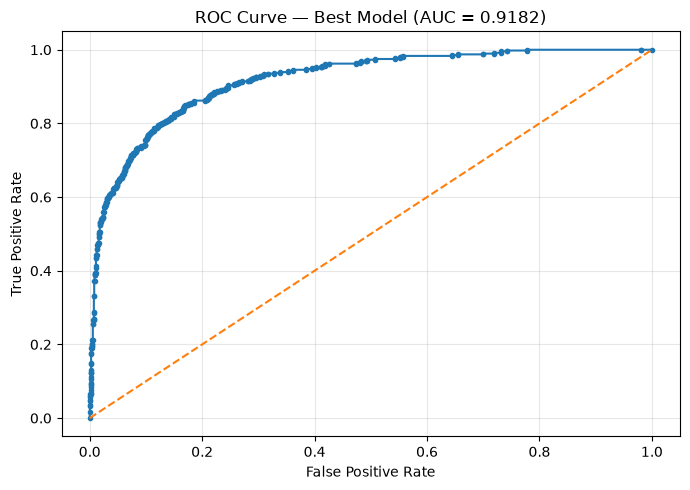

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\10_best_model_precision_recall_curve.png


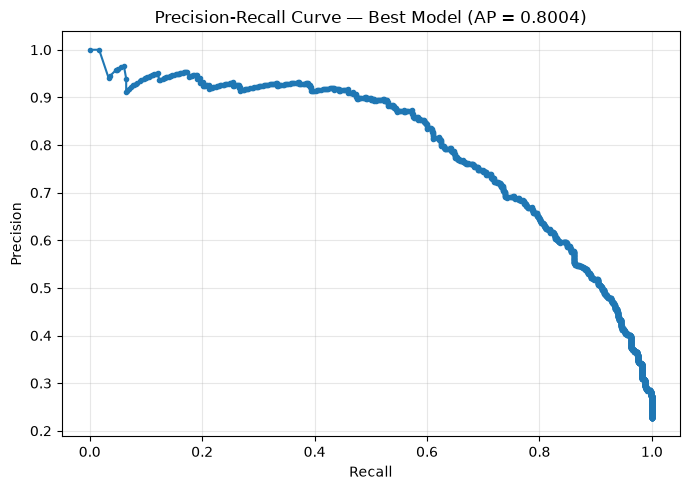

In [20]:
positive_index = list(label_encoder.classes_).index("Positive")
y_score = y_prob[:, positive_index]
y_true_positive = (y_true == positive_index).astype(int)

# ROC curve
if len(np.unique(y_true_positive)) == 2:
    fpr, tpr, _ = roc_curve(y_true_positive, y_score)
    roc_auc = roc_auc_score(y_true_positive, y_score)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, marker=".")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.title(f"ROC Curve — Best Model (AUC = {roc_auc:.4f})")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.grid(True, alpha=0.3)
    save_current_fig("09_best_model_roc_curve.png")

    precision, recall, _ = precision_recall_curve(y_true_positive, y_score)
    ap = average_precision_score(y_true_positive, y_score)

    plt.figure(figsize=(7, 5))
    plt.plot(recall, precision, marker=".")
    plt.title(f"Precision-Recall Curve — Best Model (AP = {ap:.4f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.grid(True, alpha=0.3)
    save_current_fig("10_best_model_precision_recall_curve.png")
else:
    print("ROC/PR curves skipped because test set does not contain both classes.")

## 19. Per-aspect test evaluation

This helps you explain whether the model performs consistently across Shopee aspects.

,aspects,support,accuracy,macro_f1,weighted_f1,positive_support,negative_support
0,App_experience,731,0.963064,0.885221,0.962676,66,665
1,Customer_service,85,0.882353,0.879535,0.881919,37,48
2,Trust,594,0.840067,0.814908,0.842939,175,419
3,Item_quality,72,0.805556,0.797915,0.808830,26,46
4,Pricing,158,0.791139,0.786618,0.790943,90,68
5,Information,38,0.868421,0.768010,0.864405,7,31
6,Payment,55,0.909091,0.697470,0.904490,5,50
7,Shipping,171,0.824561,0.670139,0.816642,30,141
8,Delivered_product_status,142,0.732394,0.598512,0.732394,30,112
9,Product_availability,15,0.600000,0.598214,0.596429,8,7


Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\11_per_aspect_macro_f1_test.png


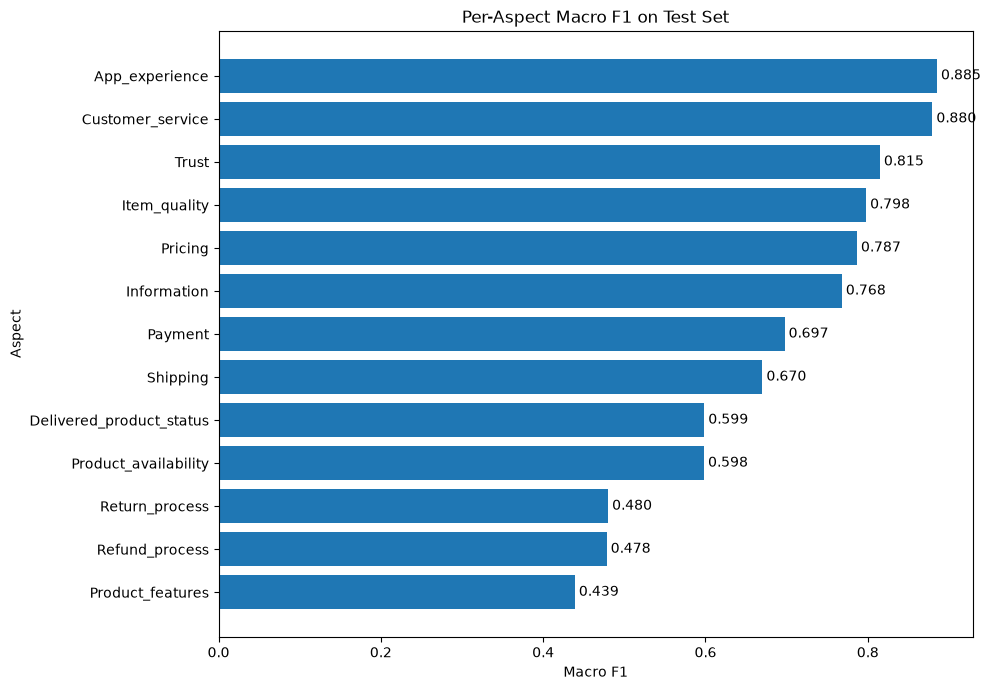

In [21]:
def per_group_metrics(data, group_col="aspects"):
    rows = []

    for group_value, group_df in data.groupby(group_col):
        y_t = label_encoder.transform(group_df["true_sentiment"])
        y_p = label_encoder.transform(group_df["pred_sentiment"])

        row = {
            group_col: group_value,
            "support": len(group_df),
            "accuracy": accuracy_score(y_t, y_p),
            "macro_f1": f1_score(y_t, y_p, average="macro", zero_division=0),
            "weighted_f1": f1_score(y_t, y_p, average="weighted", zero_division=0),
            "positive_support": int((group_df["true_sentiment"] == "Positive").sum()),
            "negative_support": int((group_df["true_sentiment"] == "Negative").sum()),
        }
        rows.append(row)

    return pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)

per_aspect_df = per_group_metrics(test_pred_df, group_col="aspects")
display(per_aspect_df)

per_aspect_df.to_csv(OUTPUT_DIR / "phase3_per_aspect_test_metrics.csv", index=False, encoding="utf-8-sig")

# Plot per-aspect Macro F1
plot_aspect = per_aspect_df.sort_values("macro_f1", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(plot_aspect["aspects"], plot_aspect["macro_f1"])
plt.title("Per-Aspect Macro F1 on Test Set")
plt.xlabel("Macro F1")
plt.ylabel("Aspect")

for i, v in enumerate(plot_aspect["macro_f1"].values):
    plt.text(v, i, f" {v:.3f}", va="center")

save_current_fig("11_per_aspect_macro_f1_test.png")

## 20. Error analysis sample

Use this table to inspect where the model makes mistakes.

In [22]:
errors_df = test_pred_df[test_pred_df["is_correct"] == False].copy()
errors_df = errors_df.sort_values(["aspects", "true_sentiment", "pred_sentiment"]).reset_index(drop=True)

print("Total test errors:", len(errors_df))
display(errors_df[[
    "id", "reviews", "aspects", "true_sentiment", "pred_sentiment",
    "prob_Negative", "prob_Positive"
]].head(50))

errors_df.to_csv(OUTPUT_DIR / "phase3_error_analysis.csv", index=False, encoding="utf-8-sig")

Total test errors: 270


,id,reviews,aspects,true_sentiment,pred_sentiment,prob_Negative,prob_Positive
0,d8f09aaabe492694,"Pig commercials, they make very small x-button...",App_experience,Negative,Positive,3.383295e-02,0.966167
1,d5561b6648bd9d7a,Since there's a live one..the apps are heavy a...,App_experience,Negative,Positive,6.991636e-02,0.930084
2,965fc8244e5ce9ff,Love you. Nice. The app made it easier to shop.,App_experience,Negative,Positive,1.448943e-07,1.000000
3,3c4b709ea03e6031,"Good app, stuff is good, but my shopee apps ar...",App_experience,Negative,Positive,8.310394e-04,0.999169
4,51009c7a6e353b73,"Please step up again, give me a digital paymen...",App_experience,Negative,Positive,6.177116e-03,0.993823
5,d2ca35b43daee24a,It's a good app. Just don't ask me again. It's...,App_experience,Negative,Positive,8.163287e-03,0.991837
6,8300f8e3db85a3b1,"The app can't search for goods, but the signal...",App_experience,Negative,Positive,7.041179e-03,0.992959
7,067bdaf883104d97,We won't use this application.,App_experience,Negative,Positive,6.555355e-02,0.934446
8,1b973a4801cf6b7f,do not use this application this application i...,App_experience,Negative,Positive,1.987829e-02,0.980122
9,9cbc3ce092838d63,It's good. It's just a slow delivery.,App_experience,Negative,Positive,8.448488e-02,0.915515


## 21. Final summary for skripsi documentation

This cell creates a short text summary that you can adapt into your methodology/evaluation chapter.

In [23]:
summary_text = (
    "PHASE 3 SUMMARY - BiLSTM with SMOTE\n\n"
    "Dataset:\n"
    f"- Total aspect-level rows used: {len(df):,}\n"
    f"- Unique reviews: {df['id'].nunique():,}\n"
    "- Input format: [ASPECT] aspect_name [REVIEW] review_text\n"
    f"- Target label: sentiment polarity ({', '.join(label_encoder.classes_)})\n\n"
    "Split strategy:\n"
    "- Grouped by review id to prevent the same review appearing in train/validation/test.\n"
    f"- Train rows: {len(train_df):,}\n"
    f"- Validation rows: {len(val_df):,}\n"
    f"- Test rows: {len(test_df):,}\n\n"
    "SMOTE:\n"
    "- Applied only to the training set after TF-IDF, TruncatedSVD, and StandardScaler.\n"
    "- Validation and test sets were not resampled.\n\n"
    "Experiment:\n"
    f"- Number of BiLSTM configurations tested: {len(CONFIGS)}\n"
    f"- Best configuration: {best_config['name']}\n"
    f"- Best validation macro F1: {best_overall['val_macro_f1']:.4f}\n\n"
    "Final test result:\n"
    f"- Accuracy: {test_metrics['accuracy']:.4f}\n"
    f"- Macro F1: {test_metrics['macro_f1']:.4f}\n"
    f"- Weighted F1: {test_metrics['weighted_f1']:.4f}\n"
    f"- ROC-AUC: {test_metrics['roc_auc']:.4f}\n"
    f"- Average Precision: {test_metrics['average_precision']:.4f}\n"
)

print(summary_text)

with open(OUTPUT_DIR / "phase3_skripsi_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary_text)

print(f"Saved summary to: {OUTPUT_DIR / 'phase3_skripsi_summary.txt'}")

PHASE 3 SUMMARY - BiLSTM with SMOTE

Dataset:
- Total aspect-level rows used: 10,781
- Unique reviews: 7,577
- Input format: [ASPECT] aspect_name [REVIEW] review_text
- Target label: sentiment polarity (Negative, Positive)

Split strategy:
- Grouped by review id to prevent the same review appearing in train/validation/test.
- Train rows: 7,593
- Validation rows: 1,079
- Test rows: 2,109

SMOTE:
- Applied only to the training set after TF-IDF, TruncatedSVD, and StandardScaler.
- Validation and test sets were not resampled.

Experiment:
- Number of BiLSTM configurations tested: 10
- Best configuration: config_08_seq8
- Best validation macro F1: 0.8412

Final test result:
- Accuracy: 0.8720
- Macro F1: 0.8195
- Weighted F1: 0.8727
- ROC-AUC: 0.9182
- Average Precision: 0.8004

Saved summary to: C:\Users\Lenovo\Documents\Skripsi\dataset\phase3\phase3_bilstm_smote_outputs\phase3_skripsi_summary.txt
